# What makes each AI write differently?

**The game:** we get a short piece of text and must guess which of **18 AI models** wrote it.

This notebook looks at the training data (`data/train.csv`) and asks: *what clues give each model away?*

**How to read the colours in this notebook**
- Each **model family** (company) has its own colour: Claude, Gemini, GPT, GLM, Kimi, Qwen.
- In the **heatmaps** (coloured grids):
  - **orange** means "more than usual"
  - **blue** means "less than usual"
  - **grey or white** means "about normal"
  - the stronger the colour, the bigger the difference.
- In the **"how often" grids**, darker blue simply means "more".

In [1]:
import re, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

ROOT = "../"
t = pd.read_csv(ROOT + "data/train.csv")
t["text"] = t.text.fillna("").astype(str)

FAMILIES = ["claude", "gemini", "gpt", "glm", "kimi", "qwen"]
FAM_COLOR = dict(zip(FAMILIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
fam = lambda m: next(f for f in FAMILIES if m.startswith(f))
t["family"] = t.model.map(fam)
MODELS = sorted(t.model.unique(), key=lambda m: (FAMILIES.index(fam(m)), m))  # grouped by family

# colour maps: diverging (blue = less, grey = normal, orange = more) and sequential (light = little, dark blue = a lot)
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#ecebe6", "#f3a17f", "#b8431a"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f7f7f4", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False, "font.size": 10})
legend = [Patch(color=FAM_COLOR[f], label=f) for f in FAMILIES]

def family_lines(ax, n_cols=True):
    """thin white lines between families on a heatmap"""
    edges = np.cumsum([sum(fam(m) == f for m in MODELS) for f in FAMILIES])[:-1] - 0.5
    for e in edges:
        ax.axhline(e, color="white", lw=3)
        if n_cols: ax.axvline(e, color="white", lw=3)

def colour_labels(ax, axis="y"):
    labels = ax.get_yticklabels() if axis == "y" else ax.get_xticklabels()
    for lab in labels:
        lab.set_color(FAM_COLOR[fam(lab.get_text())]); lab.set_fontweight("bold")

print(len(t), "texts |", t.model.nunique(), "models |", t.prompt_id.nunique(), "prompts")

2699 texts | 18 models | 150 prompts


## 1. Is the game fair? (how many texts per model)

Before looking for clues, check the basics.
- If one model had far more texts than the others, a lazy guesser could just always pick that model.
- Here every model has about **150 texts**.
- Each of the 150 prompts (questions) was answered by **all 18 models**.

That second point matters a lot. The **topic can never give the answer away**, because every model wrote about every topic. The only clues are *how* each model writes.

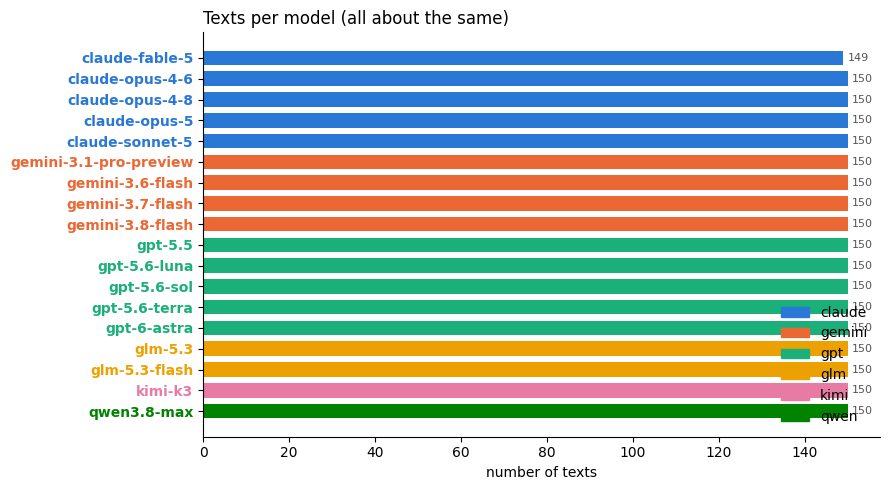

In [2]:
counts = t.model.value_counts().reindex(MODELS)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(MODELS, counts, color=[FAM_COLOR[fam(m)] for m in MODELS], height=0.7)
ax.invert_yaxis(); ax.set_xlabel("number of texts"); ax.set_title("Texts per model (all about the same)", loc="left")
for i, v in enumerate(counts): ax.text(v + 1, i, str(v), va="center", fontsize=8, color="#555")
ax.legend(handles=legend, loc="lower right", frameon=False); colour_labels(ax)
plt.tight_layout(); plt.show()

## 2. Do some models write longer answers?

You might expect some AIs to be chatty and others short. This chart shows **how many words** each text has, one box per model.
- The **box** covers the middle half of that model's texts.
- The **line inside** the box is the typical length.

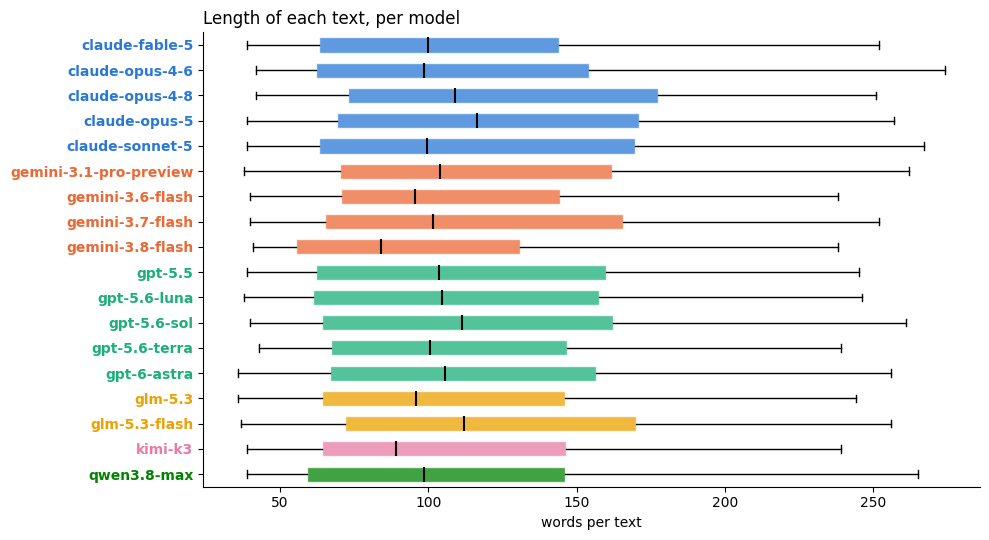

In [3]:
words = t.text.str.split().str.len()
fig, ax = plt.subplots(figsize=(10, 5.5))
bp = ax.boxplot([words[t.model == m] for m in MODELS], vert=False, widths=0.6, patch_artist=True, showfliers=False,
                medianprops=dict(color="black", lw=1.5))
for patch, m in zip(bp["boxes"], MODELS): patch.set_facecolor(FAM_COLOR[fam(m)]); patch.set_alpha(0.75); patch.set_edgecolor("white")
ax.set_yticks(range(1, len(MODELS) + 1), MODELS); ax.invert_yaxis(); colour_labels(ax)
ax.set_xlabel("words per text"); ax.set_title("Length of each text, per model", loc="left")
plt.tight_layout(); plt.show()

**What this shows:** the boxes **overlap almost completely**. Every model writes a short paragraph of roughly 80 to 120 words.

So **length is a useless clue**. Something else must give them away.

(Also, no model ever uses headings, bullet points, bold text, tables, emoji or even line breaks. Every text is one plain paragraph, so formatting gives no clues either.)

## 3. The style fingerprint (the most important chart)

Here we measure small writing habits, like how often a model uses a certain punctuation mark. Then we compare each model with the average of all 18.

**How to read it:**
- Each **row** is a model, grouped by family (white lines separate the families).
- Each **column** is a habit.
- The **number** in a cell is the real average for that model.
- The **colour** says how far that is from normal:
  - **orange** means this model does it much **more** than others
  - **blue** means much **less**

A few habits explained:
- **em dash** is the long dash `—` that some writers use instead of commas.
- **curly quotes** are fancy quote marks `’ “ ”` instead of plain `' "`.
- **"per 1k words"** means "how many times per 1,000 words".

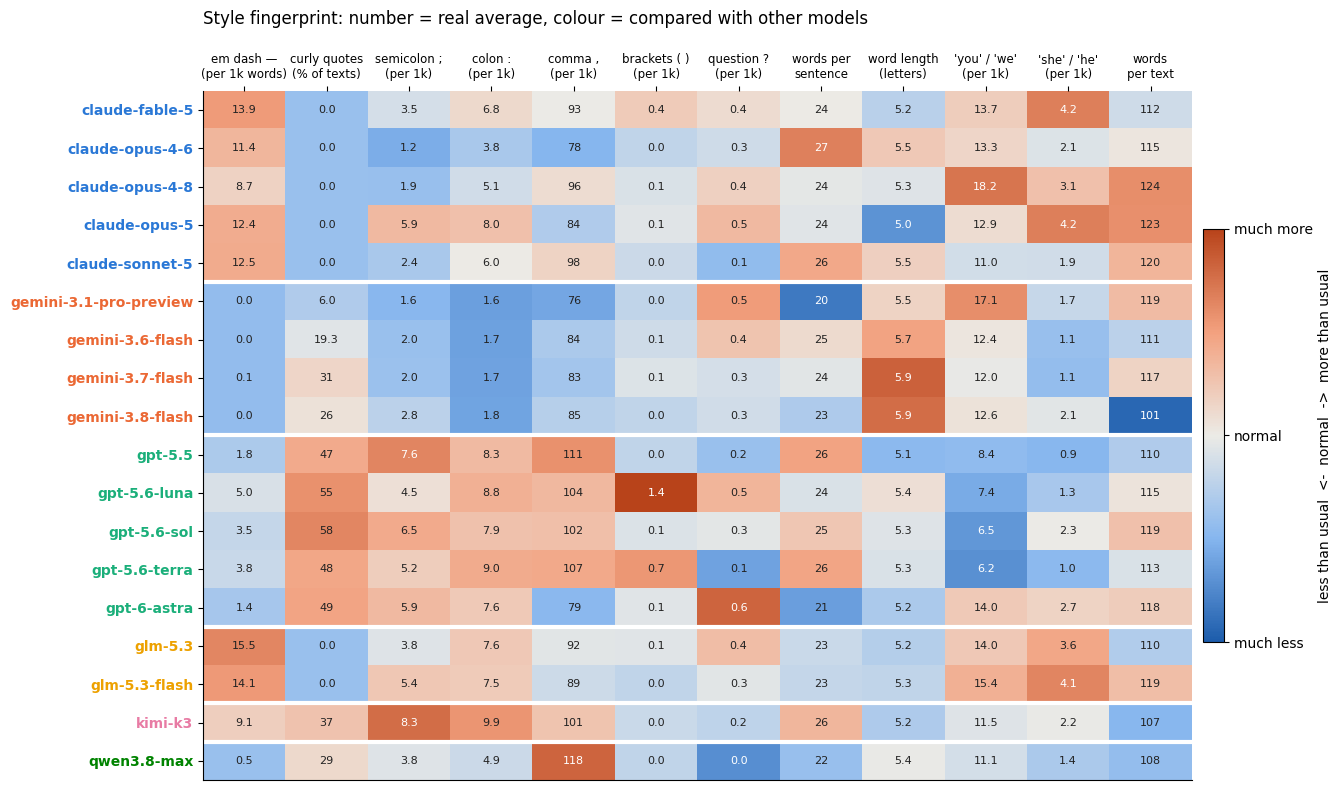

In [4]:
wc = words.clip(lower=1)
per1k = lambda pat: t.text.str.count(pat) / wc * 1000
feat = pd.DataFrame({
    "em dash —\n(per 1k words)": per1k("—"),
    "curly quotes\n(% of texts)": t.text.str.contains("[’“”]") * 100,
    "semicolon ;\n(per 1k)": per1k(";"),
    "colon :\n(per 1k)": per1k(":"),
    "comma ,\n(per 1k)": per1k(","),
    "brackets ( )\n(per 1k)": per1k(r"\("),
    "question ?\n(per 1k)": per1k(r"\?"),
    "words per\nsentence": t.text.apply(lambda s: len(s.split()) / max(1, len(re.findall(r"[.!?](\s|$)", s)))),
    "word length\n(letters)": t.text.apply(lambda s: np.mean([len(w) for w in re.findall(r"[A-Za-z]+", s)] or [0])),
    "'you' / 'we'\n(per 1k)": t.text.str.lower().str.count(r"\b(you|your|we|our)\b") / wc * 1000,
    "'she' / 'he'\n(per 1k)": t.text.str.lower().str.count(r"\b(she|her|he|his|him)\b") / wc * 1000,
    "words\nper text": words,
})
avg = feat.groupby(t.model).mean().reindex(MODELS)
z = (avg - avg.mean()) / avg.std()          # how many "steps" each model is from the average model
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(z.values, cmap=DIV, norm=TwoSlopeNorm(0, -2.5, 2.5), aspect="auto")
for i in range(len(MODELS)):
    for j in range(z.shape[1]):
        v = avg.values[i, j]
        ax.text(j, i, f"{v:.0f}" if v >= 20 else f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(z.values[i, j]) > 1.6 else "#222")
ax.set_xticks(range(z.shape[1]), z.columns, fontsize=8.5); ax.xaxis.tick_top()
ax.set_yticks(range(len(MODELS)), MODELS); colour_labels(ax); family_lines(ax, n_cols=False)
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01); cb.set_label("less than usual  <-  normal  ->  more than usual")
cb.set_ticks([-2.5, 0, 2.5], labels=["much less", "normal", "much more"])
ax.set_title("Style fingerprint: number = real average, colour = compared with other models\n", loc="left")
plt.tight_layout(); plt.show()

**What patterns jump out:**

1. **Em dash, first column.** Claude and GLM are orange: they love the long dash. Gemini and Qwen are deep blue: they almost never use it. GPT sits in between.
2. **Curly quotes, second column.** Claude and GLM are **0%**: they *never* use fancy quotes. GPT uses them in about half its texts. If you see a `’`, it is almost certainly **not** Claude or GLM.
3. **Colons.** Gemini is blue: it almost never uses `:`.
4. **Semicolons.** Kimi and the GPTs use more `;`.

Notice the colours make **horizontal stripes per family**. Models from the same company share habits, probably because they were trained in similar ways. That is great for guessing the **company**, but it makes guessing the exact **version** hard.

## 4. Two clues on one map

Let's take the two strongest clues (em dashes and curly quotes) and plot every model as a dot.
- The further **right** a dot is, the more em dashes.
- The **higher** it is, the more curly quotes.

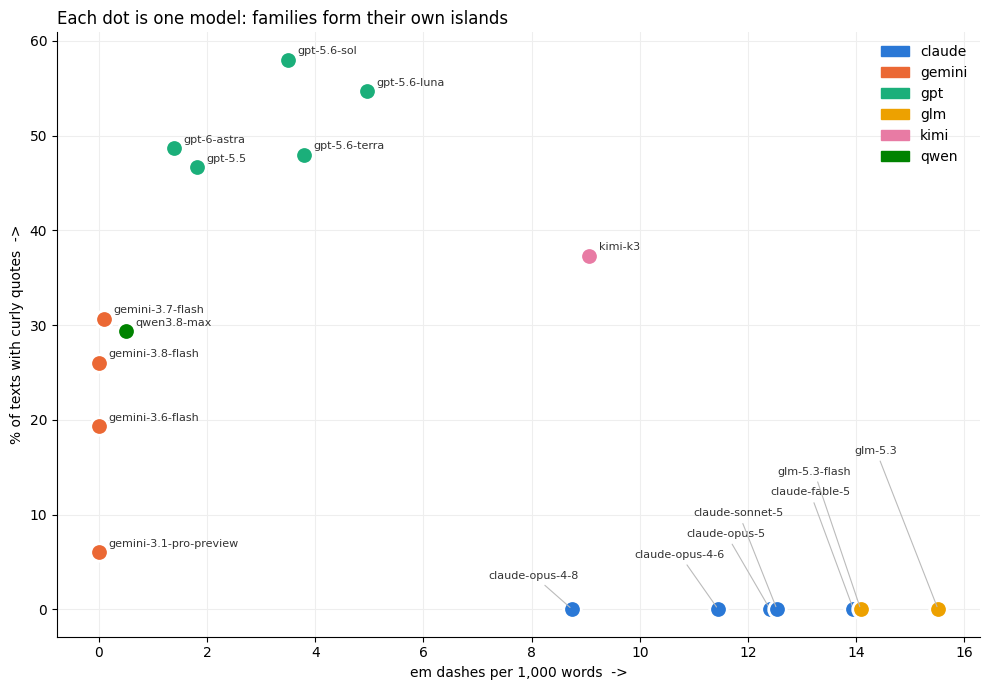

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))
x, y = avg.iloc[:, 0], avg.iloc[:, 1]
low = sorted([m for m in MODELS if y[m] < 3], key=lambda m: x[m])   # crowded row at the bottom: stack labels upward
for m in MODELS:
    ax.scatter(x[m], y[m], s=160, color=FAM_COLOR[fam(m)], edgecolor="white", lw=2, zorder=3)
    if m in low:
        i = low.index(m)
        ax.annotate(m, (x[m], y[m]), xytext=(-60, 22 + 15 * i), textcoords="offset points", fontsize=8, color="#333",
                    arrowprops=dict(arrowstyle="-", color="#bbb", lw=0.8))
    else:
        ax.annotate(m, (x[m], y[m]), xytext=(7, 4), textcoords="offset points", fontsize=8, color="#333")
ax.set_xlabel("em dashes per 1,000 words  ->"); ax.set_ylabel("% of texts with curly quotes  ->")
ax.grid(True, color="#eee", lw=0.8); ax.set_axisbelow(True)
ax.legend(handles=legend, frameon=False, loc="upper right")
ax.set_title("Each dot is one model: families form their own islands", loc="left")
plt.tight_layout(); plt.show()

**What this shows:** the dots group into **islands by colour**.
- **Bottom right:** Claude and GLM (lots of dashes, no curly quotes).
- **Top middle:** GPT (few dashes, many curly quotes).
- **Bottom left:** Gemini and Qwen (no dashes).

With only two simple counts you can already guess the family quite well. But look *inside* an island: the GPTs sit right on top of each other, and so do the Geminis. These two clues can't separate versions.

## 5. Favourite words

Every model has pet words it uses more than the others. For each family we found the words it overuses most. Then we checked how often **every** model uses them.

**How to read it:**
- **Rows** are words.
- **Columns** are models.
- **Orange** means that model uses the word more than the average model (dark orange is about 4x more).
- **Blue** means it uses the word less.

claude  favourite words: barely, consider, doesn't, since, notice
gemini  favourite words: vibrant, tapestry, monumental, completely, massive
gpt     favourite words: make, practical, mean, useful, less
glm     favourite words: off, knew, it's, ones, ten
kimi    favourite words: patience, lightning, go, keeps, bright
qwen    favourite words: forests, becoming, loss, turning, feed


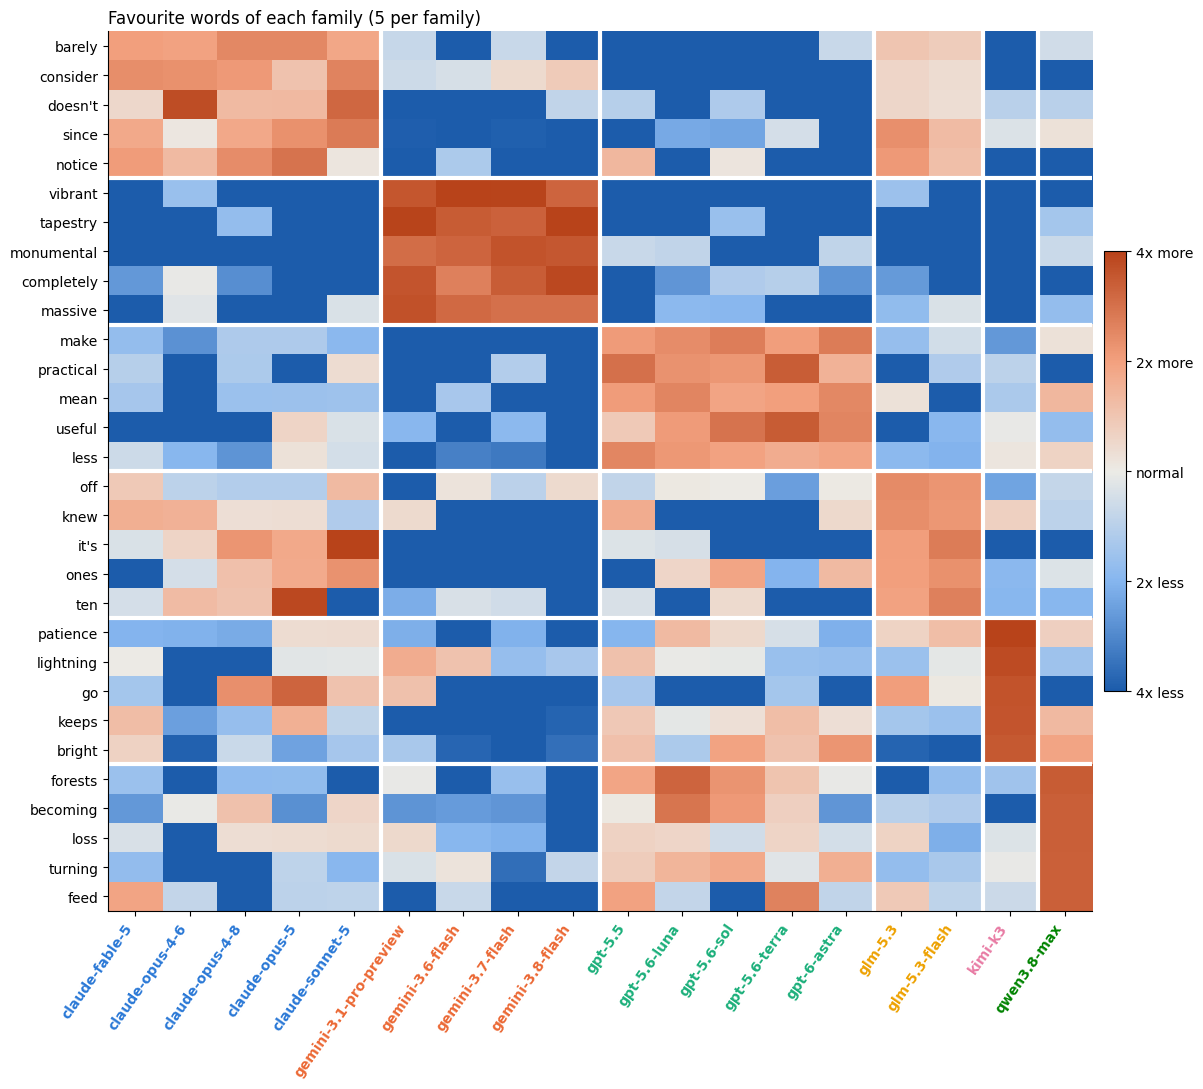

In [6]:
tok = t.text.str.lower().str.replace("\u2019", "'").str.findall(r"[a-z]+(?:'[a-z]+)?")
cnt = {m: collections.Counter(w for ws in tok[t.model == m] for w in ws) for m in MODELS}
tot_m = {m: sum(c.values()) for m, c in cnt.items()}
rate = pd.DataFrame({m: {w: c / tot_m[m] for w, c in cnt[m].items()} for m in MODELS}).fillna(0)  # share of words
rate = rate[(rate * pd.Series(tot_m)).sum(axis=1) >= 25]                                               # common enough
ratio = np.log2((rate + 2e-5).div(rate.mean(axis=1) + 2e-5, axis=0))                                    # vs average model
picked = []
for f in FAMILIES:
    cols = [m for m in MODELS if fam(m) == f]
    score = ratio[cols].mean(axis=1) - 0.5 * ratio[cols].std(axis=1).fillna(0)  # high for the whole family, not one model
    top = [w for w in score.sort_values(ascending=False).index if w not in picked and len(w) > 1][:5]
    picked += top
    print(f"{f:7s} favourite words: {', '.join(top)}")
R = ratio.loc[picked, MODELS]
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(R.values, cmap=DIV, norm=TwoSlopeNorm(0, -2, 2), aspect="auto")
ax.set_yticks(range(len(picked)), picked); ax.set_xticks(range(len(MODELS)), MODELS, rotation=55, ha="right")
colour_labels(ax, "x")
for k in range(1, len(FAMILIES)): ax.axhline(5 * k - 0.5, color="white", lw=3)
edges = np.cumsum([sum(fam(m) == f for m in MODELS) for f in FAMILIES])[:-1] - 0.5
for e in edges: ax.axvline(e, color="white", lw=3)
cb = fig.colorbar(im, ax=ax, shrink=0.5, pad=0.01)
cb.set_ticks([-2, -1, 0, 1, 2], labels=["4x less", "2x less", "normal", "2x more", "4x more"])
ax.set_title("Favourite words of each family (5 per family)", loc="left")
plt.tight_layout(); plt.show()

**What this shows:** look for the **orange blocks along the diagonal**. Each family's words light up mostly under that family's own models.

The list printed above the chart gives each family's top 5 words. They hint at a "personality" for each family:
- **Gemini** goes big and dramatic (words like *vibrant, tapestry, monumental, massive*).
- **GPT** is practical and explains things (*make, practical, useful, mean*).
- **Claude** is thoughtful and careful (*barely, consider, notice, since*).

Kimi and Qwen are single models, so their rows show only that one model's pet words.

These are the kinds of patterns our AI models learn automatically, just with thousands of words at once instead of five.

## 6. Which models write alike?

Now we compare every model with every other model using its whole writing style (all the little letter patterns at once).

**How to read it:**
- This is a grid of models against models.
- **Orange** means the two models write **very alike**.
- **Blue** means they write **differently**.
- The diagonal (a model compared with itself) is always the most orange.

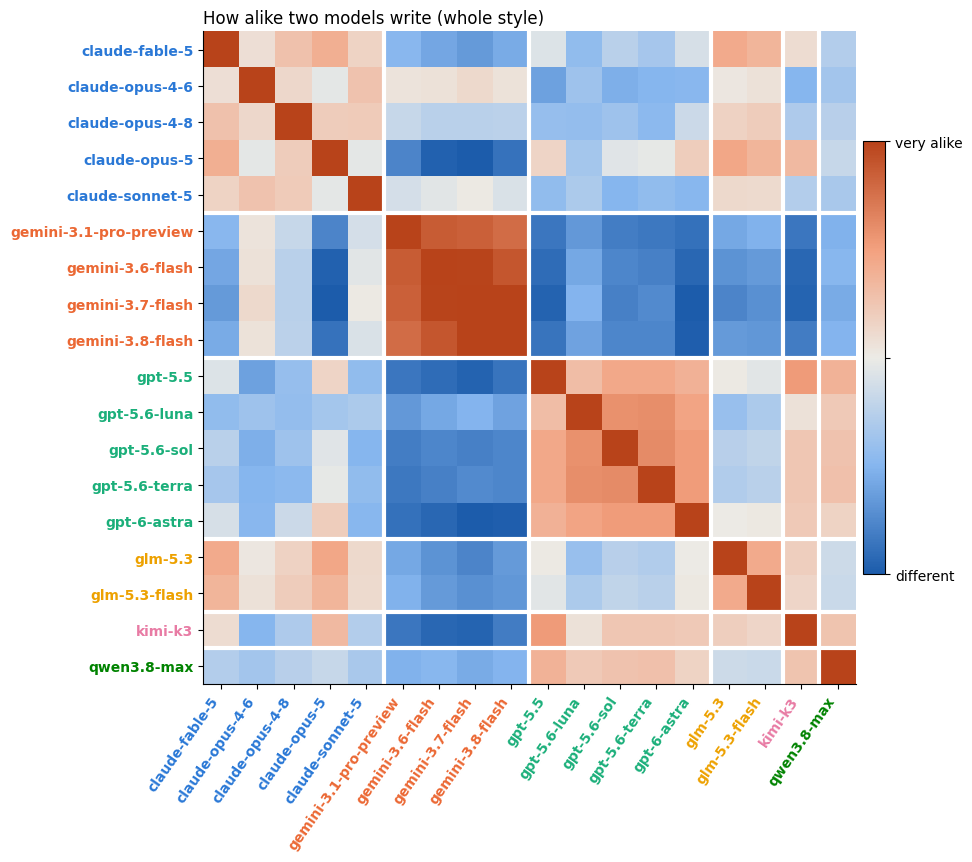

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True, max_features=60000).fit_transform(t.text)
cent = np.vstack([np.asarray(X[(t.model == m).to_numpy()].mean(0)).ravel() for m in MODELS])
cent -= cent.mean(0)                                   # remove what all models share, keep what is special
cent /= np.linalg.norm(cent, axis=1, keepdims=True)
S = pd.DataFrame(cent @ cent.T, MODELS, MODELS)
fig, ax = plt.subplots(figsize=(10, 9))
off = S.values[~np.eye(len(MODELS), dtype=bool)]
im = ax.imshow(S.values, cmap=DIV, norm=TwoSlopeNorm(0, off.min(), off.max()))
ax.set_xticks(range(len(MODELS)), MODELS, rotation=55, ha="right"); ax.set_yticks(range(len(MODELS)), MODELS)
colour_labels(ax); colour_labels(ax, "x"); family_lines(ax)
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01); cb.set_ticks([off.min(), 0, off.max()], labels=["different", "", "very alike"])
ax.set_title("How alike two models write (whole style)", loc="left")
plt.tight_layout(); plt.show()

**What this shows:** orange **squares along the diagonal**, but they are not equally strong.
- **Gemini** is one big dark-orange square. All four Gemini models write almost the same way.
- **GPT** is also a clear orange square: the five GPTs are close siblings.
- **Claude's** square is much paler. The Claude versions are *less* alike than the Geminis are. That is good news: different versions are easier to tell apart. Chart 7 confirms it.
- **GLM** looks a bit like Claude (orange cells between them), and **Kimi and Qwen** lean slightly towards GPT.

Between Gemini and the rest it is deep blue. Gemini has the most "unique" house style of all.

## 7. Where does our model make mistakes?

Finally, the real test. This is a **confusion matrix** for our Qwen3-4B classifier.

**Where these predictions come from:** each text was predicted by a model that **never saw it during training** (out-of-fold, 2,160 texts). So these are honest results.

**How to read it:**
- Each **row** is the *true* model.
- Each **column** is what we *guessed*.
- A row adds up to 100%.
- Dark cells on the **diagonal** are correct guesses.
- Dark cells **off** the diagonal are mix-ups.

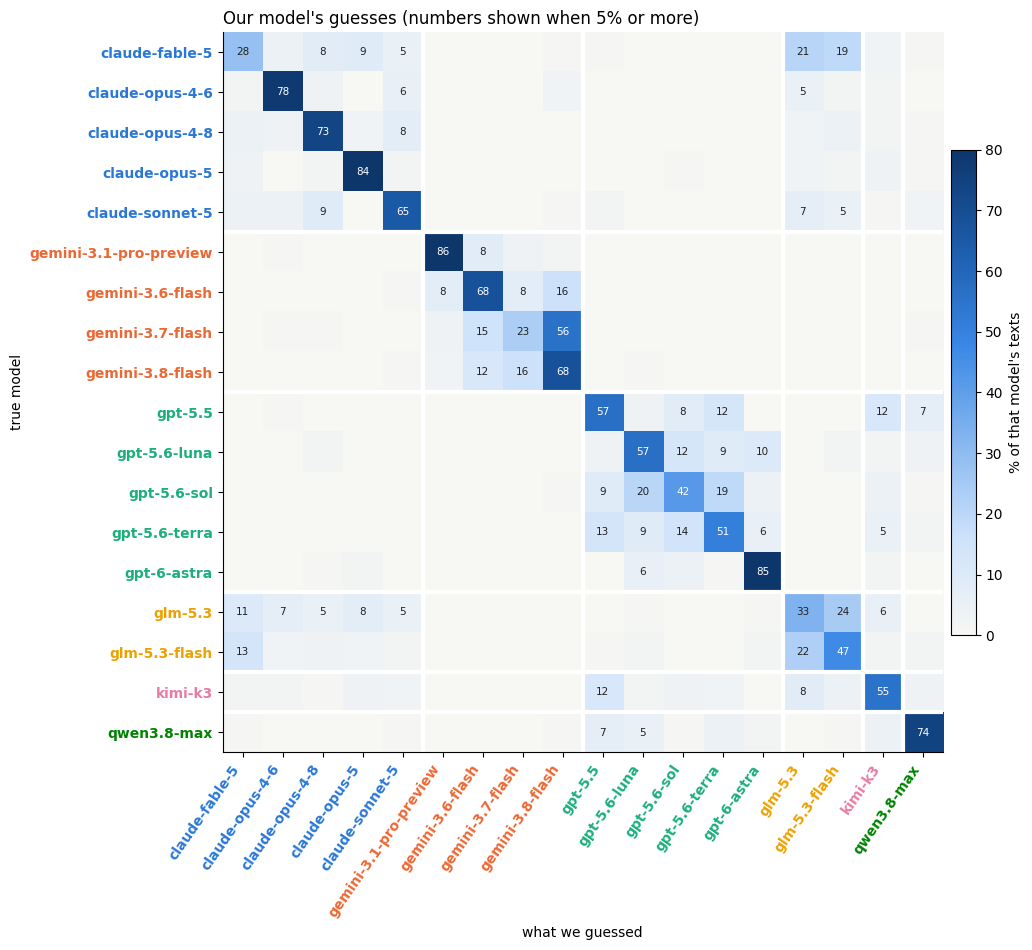

exact model right: 60%
company (family) right: 84%
of the mistakes, 61% picked a sibling from the SAME family


In [8]:
d = np.load(ROOT + "data/processed/blend_parts.npz", allow_pickle=True)
classes = sorted(t.model.unique())
truth = pd.Series(d["ids"].astype(str)).map(t.assign(id=t.id.astype(str)).set_index("id").model)
assert (truth.map({c: i for i, c in enumerate(classes)}).to_numpy() == d["y"]).all()
pred = np.array(classes)[d["s4"].argmax(1)]
cm = pd.crosstab(truth.to_numpy(), pred, normalize="index").reindex(index=MODELS, columns=MODELS).fillna(0) * 100
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cm.values, cmap=SEQ, vmin=0, vmax=80)
for i in range(len(MODELS)):
    for j in range(len(MODELS)):
        if cm.values[i, j] >= 5:
            ax.text(j, i, f"{cm.values[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if cm.values[i, j] > 40 else "#222")
ax.set_xticks(range(len(MODELS)), MODELS, rotation=55, ha="right"); ax.set_yticks(range(len(MODELS)), MODELS)
ax.set_xlabel("what we guessed"); ax.set_ylabel("true model"); colour_labels(ax); colour_labels(ax, "x"); family_lines(ax)
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01); cb.set_label("% of that model's texts")
ax.set_title("Our model's guesses (numbers shown when 5% or more)", loc="left")
plt.tight_layout(); plt.show()

right = (pred == truth.to_numpy()).mean()
same_fam = np.mean([fam(p) == fam(g) for p, g in zip(pred, truth) if p != g])
fam_acc = np.mean([fam(p) == fam(g) for p, g in zip(pred, truth)])
print(f"exact model right: {right:.0%}")
print(f"company (family) right: {fam_acc:.0%}")
print(f"of the mistakes, {same_fam:.0%} picked a sibling from the SAME family")

**What this shows:**
- Most dark cells sit **inside the family squares**. When the model is wrong, it is usually wrong about the *version*, not the *company*. It almost never mixes up Gemini with Claude.
- Look at the **gemini-3.7-flash** row. Its biggest number is under **gemini-3.8-flash**, not on the diagonal. Our model mostly thinks 3.7 *is* 3.8! (These two may simply write almost the same.)
- The three **GPT-5.6** versions (luna, sol, terra) spread their guesses over each other.
- **Claude and GLM leak into each other.** claude-fable-5 is often guessed as GLM, and glm-5.3 is often guessed as Claude. Remember from chart 3: both families love em dashes and never use curly quotes.
- The numbers printed under the chart sum it up: guessing the **company** is fairly easy, guessing the exact **version** is the hard part.

## The big picture

| What we checked | Does it help tell models apart? |
|---|---|
| Length, formatting | No, every model writes one plain ~100-word paragraph |
| Punctuation (em dash, curly quotes, colons) | Yes, strongly, but mostly for the **family** (and Claude vs GLM look alike) |
| Favourite words | Yes, also mostly for the **family** |
| Versions inside a family | Very hard: siblings share almost every habit |

**What this means for the competition:** to climb the leaderboard, we need to get better at telling **siblings apart**. For example:
- gemini 3.6 vs 3.7 vs 3.8
- the GPT-5.6 trio (luna, sol and terra)
- the Claude Opus versions

One idea is a second "specialist" model for each family, trained only to separate its siblings.